In [1]:
#implementation des bibliotheque
import pandas as pd
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

In [2]:
#implementation de data set
df=pd.read_csv('diabetes3.csv')

In [3]:
#pour l'affichage
df.head(10)

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,59.0,F,32.1,NaN,157.0,93.2,38.0,4.00,4.8598,87.0,151
1,48.0,M,21.6,87.0,183.0,103.2,70.0,NaN,3.8918,69.0,75
2,NaN,NaN,30.5,93.0,156.0,93.6,41.0,NaN,4.6728,85.0,141
3,24.0,M,NaN,84.0,198.0,131.4,40.0,5.00,4.8903,89.0,206
4,NaN,M,23.0,101.0,192.0,125.4,52.0,4.00,4.2905,80.0,135
5,23.0,M,22.6,89.0,139.0,64.8,61.0,2.00,4.1897,68.0,97
6,36.0,F,22.0,NaN,160.0,99.6,50.0,3.00,3.9512,82.0,138
7,66.0,NaN,26.2,114.0,255.0,185.0,56.0,4.55,4.2485,92.0,63
8,NaN,F,32.1,83.0,NaN,119.4,42.0,NaN,4.4773,NaN,110
9,29.0,M,NaN,85.0,180.0,93.4,43.0,4.00,5.3845,88.0,310


In [4]:
#des infos sur notre data set
print("\nData dimensions",df.shape)
print("\nData names",df.columns)
print("\nData types",df.dtypes)


Data dimensions (454, 11)

Data names Index(['AGE', 'SEX', 'BMI', 'BP', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'Y'], dtype='object')

Data types AGE    float64
SEX     object
BMI    float64
BP     float64
S1     float64
S2     float64
S3     float64
S4     float64
S5     float64
S6     float64
Y        int64
dtype: object


In [5]:
#affichage des valeur manquante
df.isnull()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,False,False,False,True,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,True,False,False,False
2,True,True,False,False,False,False,False,True,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,True,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
449,False,False,False,False,False,False,False,False,False,False,False
450,False,False,False,False,False,False,True,True,False,False,False
451,False,False,False,True,True,False,False,False,False,False,False
452,False,False,True,False,True,False,True,False,False,False,False


In [6]:
#affichage de somme des valeurs manquantes dans chaque colonne
df.isnull().sum()

AGE    45
SEX    43
BMI    49
BP     47
S1     46
S2     48
S3     46
S4     39
S5     43
S6     38
Y       0
dtype: int64

In [7]:
# remplit les valeurs manquantes  la moyenne pour les colonnes numérique, le mode pour les colonnes non numérique.
columns = df.columns[0:11]  
for col in columns:
    if df[col].isnull().sum() > 0:  
        if df[col].dtype in ['int64', 'float64']: 
            df[col].fillna(df[col].mean(), inplace=True) 
        else:
            df[col].fillna(df[col].mode()[0], inplace=True) 

In [8]:
df[col].isnull().sum()

0

In [9]:
df.head()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,59.000000,F,32.100000,94.266929,157.0,93.2,38.0,4.000,4.8598,87.0,151
1,48.000000,M,21.600000,87.000000,183.0,103.2,70.0,4.038,3.8918,69.0,75
2,48.322738,M,30.500000,93.000000,156.0,93.6,41.0,4.038,4.6728,85.0,141
3,24.000000,M,26.446173,84.000000,198.0,131.4,40.0,5.000,4.8903,89.0,206
4,48.322738,M,23.000000,101.000000,192.0,125.4,52.0,4.000,4.2905,80.0,135


In [10]:
# implementation des bibliotheque de sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

In [11]:
# Encodage de SEX parcequ'il est de type string
df['SEX'] = LabelEncoder().fit_transform(df['SEX'])

In [12]:
# Normalisation pour que toutes les variables aient la même échelle et ainsi améliorer la performance et la convergence des modèles.
columns_to_normalize = df.columns[:-1]  
scaler = MinMaxScaler()
df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

In [13]:
df.head()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,0.666667,0.0,0.580913,0.454464,0.294118,0.250251,0.207792,0.282087,0.562217,0.439394,151
1,0.483333,1.0,0.145228,0.352113,0.421569,0.300503,0.623377,0.287447,0.222437,0.166667,75
2,0.488712,1.0,0.514523,0.436620,0.289216,0.252261,0.246753,0.287447,0.496578,0.409091,141
3,0.083333,1.0,0.346314,0.309859,0.495098,0.442211,0.233766,0.423131,0.572923,0.469697,206
4,0.488712,1.0,0.203320,0.549296,0.465686,0.412060,0.389610,0.282087,0.362385,0.333333,135


In [14]:
# Séparation X / y
X = df.drop(columns=['Y'])
y = df['Y']

In [15]:
# Division en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
# Implémentation et évaluation de plusieurs modèles de régression linéaire (SGD, Ridge, Lasso, ElasticNet) avec calcul de l'erreur quadratique moyenne, du score R², et validation croisée.
from sklearn.linear_model import SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "SGDRegressor": SGDRegressor(
        max_iter=10000,            
        alpha=0.0001,              
        learning_rate='invscaling',
        eta0=0.01,                 
        tol=1e-4,                 
        random_state=42           
    ),
    "Ridge": Ridge(alpha=0.01),  
    "Lasso": Lasso(alpha=0.01),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.3)
}

from sklearn.model_selection import cross_val_score

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\n{name} :")
    print("MSE :", mean_squared_error(y_test, y_pred))
    print("R2 Score :", r2_score(y_test, y_pred))
    
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    print("Cross-Validation R² :", scores)
    print("R² moyen :", np.mean(scores))



SGDRegressor :
MSE : 3677.819925244882
R2 Score : 0.32697236741917846
Cross-Validation R² : [0.45587934 0.37421747 0.53217791 0.50491272 0.51084429]
R² moyen : 0.4756063469937212

Ridge :
MSE : 3652.6577440332935
R2 Score : 0.33157695480943183
Cross-Validation R² : [0.44903385 0.33948087 0.54057647 0.49495227 0.52327334]
R² moyen : 0.4694633583484176

Lasso :
MSE : 3652.2839358394335
R2 Score : 0.3316453603455555
Cross-Validation R² : [0.44985134 0.34003504 0.54089217 0.49479581 0.52371032]
R² moyen : 0.46985693624705754

ElasticNet :
MSE : 3653.7346512661
R2 Score : 0.33137988471352253
Cross-Validation R² : [0.44964947 0.38057874 0.52500677 0.5045796  0.50369243]
R² moyen : 0.4727014013468708


In [17]:
# Affiche les coefficients de chaque modèle dans le dictionnaire 'models'.
for name, model in models.items():
    print(f"\n{name} coefficients :")
    print(model.coef_)



SGDRegressor coefficients :
[ -7.92859797  24.7666743  112.7134113   76.58328194  -8.60653938
 -11.5508633  -61.67587352  42.13969769  97.47731168  56.40149623]

Ridge coefficients :
[-10.67476456  25.65545478 132.48875971  81.87397466 -32.86870904
  -2.24614329 -64.26931702  16.26350642 130.272349    57.46682617]

Lasso coefficients :
[-10.38607656  25.56756699 132.44950696  81.61446867 -32.33433084
  -1.39361996 -64.83803151  14.9489645  130.30300617  57.20027313]

ElasticNet coefficients :
[ -6.48830751  23.5506955  114.2073355   74.6946995  -12.13139283
 -10.99612993 -58.47972806  30.9756894  103.13430977  54.31717761]


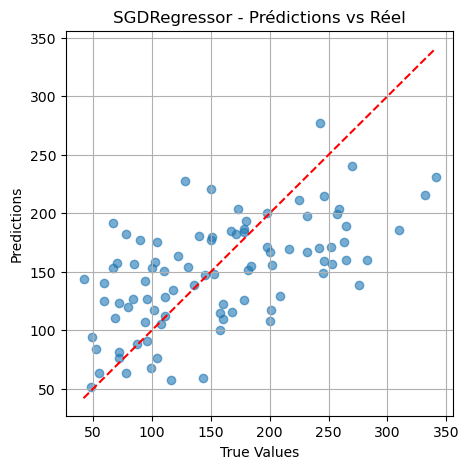

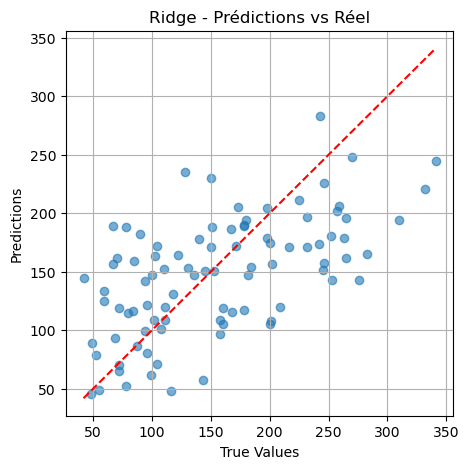

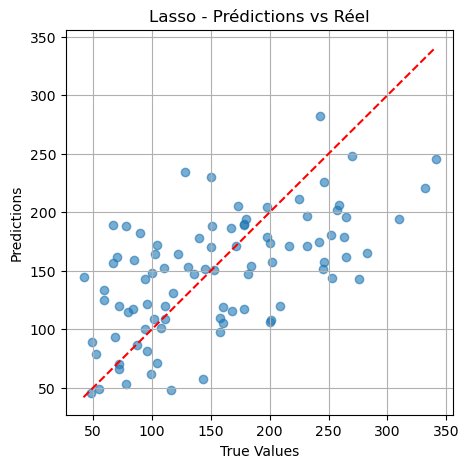

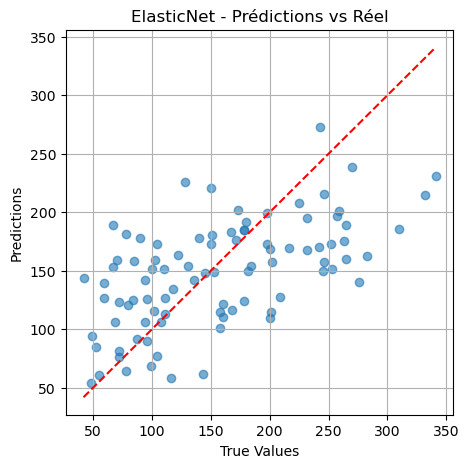

In [18]:
# Affiche un graphique comparant les valeurs réelles et les prédictions pour chaque modèle de régression.

import matplotlib.pyplot as plt

for name, model in models.items():
    y_pred = model.predict(X_test)
    plt.figure(figsize=(5, 5))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
    plt.xlabel("True Values")
    plt.ylabel("Predictions")
    plt.title(f"{name} - Prédictions vs Réel")
    plt.grid(True)
    plt.show()
